Optimal Monthly Tilt Angles:
Month 1: 34.26 degrees
Month 2: 26.64 degrees
Month 3: 15.82 degrees
Month 4: 0.00 degrees
Month 5: 5.81 degrees
Month 6: 10.32 degrees
Month 7: 8.49 degrees
Month 8: 0.77 degrees
Month 9: 0.00 degrees
Month 10: 22.61 degrees
Month 11: 32.17 degrees
Month 12: 36.34 degrees

Maximum Energy Received: 61.7041


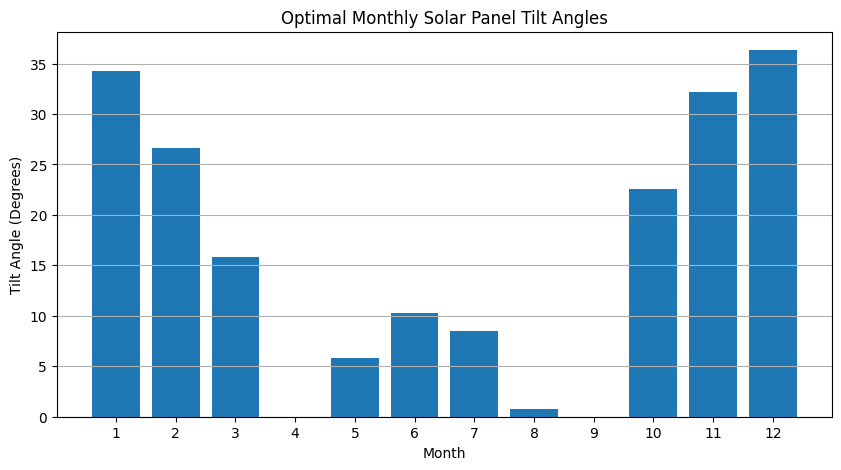

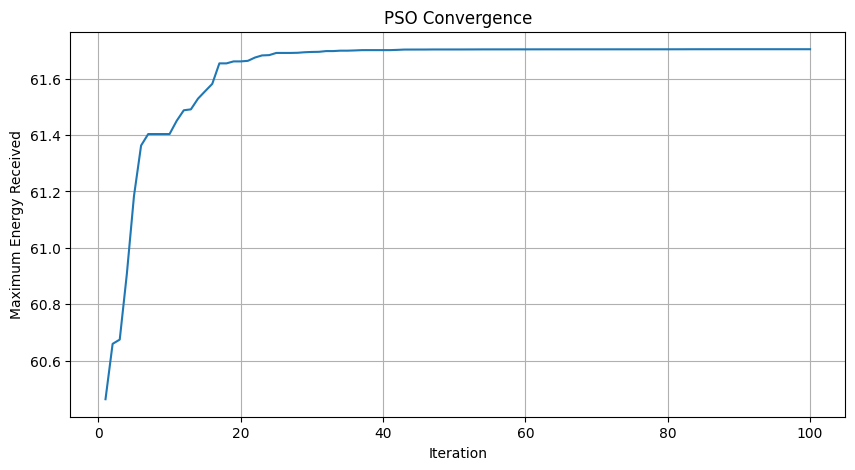

In [5]:
import numpy as np
import matplotlib.pyplot as plt

latitude = 13

irradiance = np.array([5.5, 5.8, 6.0, 5.7, 5.2, 4.5, 4.3, 4.5, 4.8, 5.0, 5.2, 5.3])
days = np.array([15, 45, 74, 105, 135, 166, 196, 227, 258, 288, 319, 349])

declination = 23.45 * np.sin(np.radians(360 * (284 + days) / 365))
ideal_tilts = np.clip(np.abs(latitude - declination), 0, 60)

def calculate_fitness(position):
    received_energy = irradiance * np.maximum(
        0,
        np.cos(np.radians(position - ideal_tilts))
    )
    return np.sum(received_energy, axis=1)

num_particles = 30
num_dimensions = 12
iterations = 100

w = 0.7
c1 = 1.5
c2 = 1.5

np.random.seed(42)

positions = np.random.uniform(0, 60, (num_particles, num_dimensions))
velocities = np.random.uniform(-5, 5, (num_particles, num_dimensions))

personal_best_positions = positions.copy()
personal_best_fitness = calculate_fitness(positions)

best_index = np.argmax(personal_best_fitness)
global_best_position = personal_best_positions[best_index].copy()
global_best_fitness = personal_best_fitness[best_index]

convergence = []

for iteration in range(iterations):
    r1 = np.random.rand(num_particles, num_dimensions)
    r2 = np.random.rand(num_particles, num_dimensions)

    velocities = (
        w * velocities
        + c1 * r1 * (personal_best_positions - positions)
        + c2 * r2 * (global_best_position - positions)
    )

    positions = np.clip(positions + velocities, 0, 60)

    fitness = calculate_fitness(positions)

    improved = fitness > personal_best_fitness

    personal_best_positions[improved] = positions[improved]
    personal_best_fitness[improved] = fitness[improved]

    best_index = np.argmax(personal_best_fitness)

    if personal_best_fitness[best_index] > global_best_fitness:
        global_best_fitness = personal_best_fitness[best_index]
        global_best_position = personal_best_positions[best_index].copy()

    convergence.append(global_best_fitness)

print("Optimal Monthly Tilt Angles:")
for month, angle in enumerate(global_best_position, 1):
    print(f"Month {month}: {angle:.2f} degrees")

print("\nMaximum Energy Received:", round(global_best_fitness, 4))

plt.figure(figsize=(10, 5))
plt.bar(range(1, 13), global_best_position)
plt.xlabel("Month")
plt.ylabel("Tilt Angle (Degrees)")
plt.title("Optimal Monthly Solar Panel Tilt Angles")
plt.xticks(range(1, 13))
plt.grid(axis="y")
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(range(1, iterations + 1), convergence)
plt.xlabel("Iteration")
plt.ylabel("Maximum Energy Received")
plt.title("PSO Convergence")
plt.grid()
plt.show()